В цьому ноутбуці відбуваєтся перевірка одного активу на рандомних відрізках часу. Метою є перевірка чи отримані загальні результати релевантні для різних режимів ринку

In [1]:
import os
os.chdir("..")

In [2]:
import pandas as pd
import numpy as np

import random
import yaml

from app import BacktestDCA
from ploter import ploter

/Users/aleksejkitajskij/Desktop/DCA/venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# stocks

In [3]:
df_stocks = pd.read_csv("data/test_crypto.csv", index_col=0, parse_dates=True)
df_stocks

,BTC,ETH,SOL,XRP,DOGE,ADA,DOT,LINK,XLM,XMR
Date,,,,,,,,,,
2014-09-17,457.334015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-18,424.440002,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-19,394.795990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-20,408.903992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2014-09-21,398.821014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
2026-10-20,82941.000000,2446.730713,106.422340,1.334452,0.081809,0.223782,1.149771,12.320927,0.181960,600.929504
2026-10-21,84011.968750,2470.766113,106.793655,1.363619,0.081867,0.224979,1.141323,12.484719,0.183488,622.434082
2026-10-22,81311.890625,2386.189209,103.542320,1.307656,0.078676,0.212025,1.111869,11.943166,0.175209,600.638428


In [4]:
df_stocks.columns

Index(['BTC', 'ETH', 'SOL', 'XRP', 'DOGE', 'ADA', 'DOT', 'LINK', 'XLM', 'XMR'], dtype='str')

In [5]:
target_asset = "BTC"
asset_prices = df_stocks[target_asset].dropna()

n_periods = 10
sequence_length = 365 * 3

periods = []
for i in range(n_periods):
    start = random.randint(0, len(asset_prices) - sequence_length)
    period_prices = asset_prices.iloc[start:start + sequence_length]
    periods.append({
        "period_id": i + 1,
        "start": period_prices.index.min(),
        "end": period_prices.index.max(),
        "prices": period_prices,
    })

In [6]:
pd.DataFrame(
    [{"period": p["period_id"], "start": p["start"], "end": p["end"], "days": len(p["prices"])} for p in periods]
 )

,period,start,end,days
0,1,2015-06-07,2018-06-05,1095
1,2,2019-07-24,2022-07-22,1095
2,3,2017-01-23,2020-01-22,1095
3,4,2017-10-15,2020-10-13,1095
4,5,2014-11-14,2017-11-12,1095
5,6,2022-11-10,2025-11-08,1095
6,7,2014-11-16,2017-11-14,1095
7,8,2022-11-06,2025-11-04,1095
8,9,2017-11-28,2020-11-26,1095
9,10,2017-04-09,2020-04-07,1095


In [7]:
strategy = {
    "buy_amount": 10,
}

01:25:38 - cmdstanpy - INFO - Chain [1] start processing
01:25:38 - cmdstanpy - INFO - Chain [1] done processing


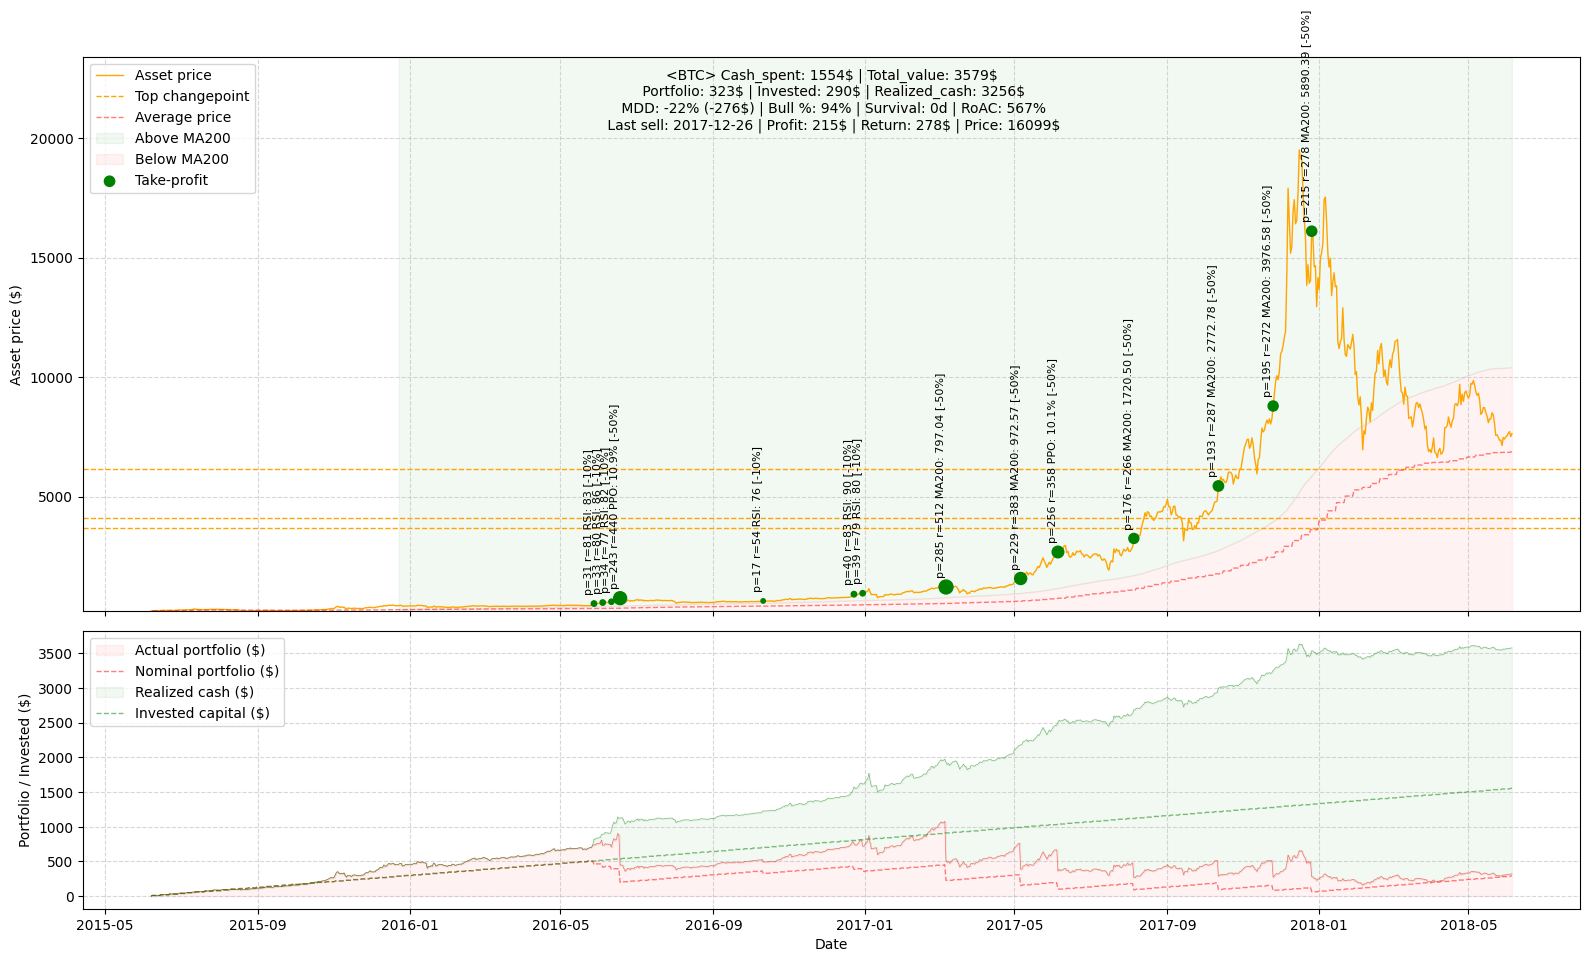

01:25:39 - cmdstanpy - INFO - Chain [1] start processing
01:25:39 - cmdstanpy - INFO - Chain [1] done processing


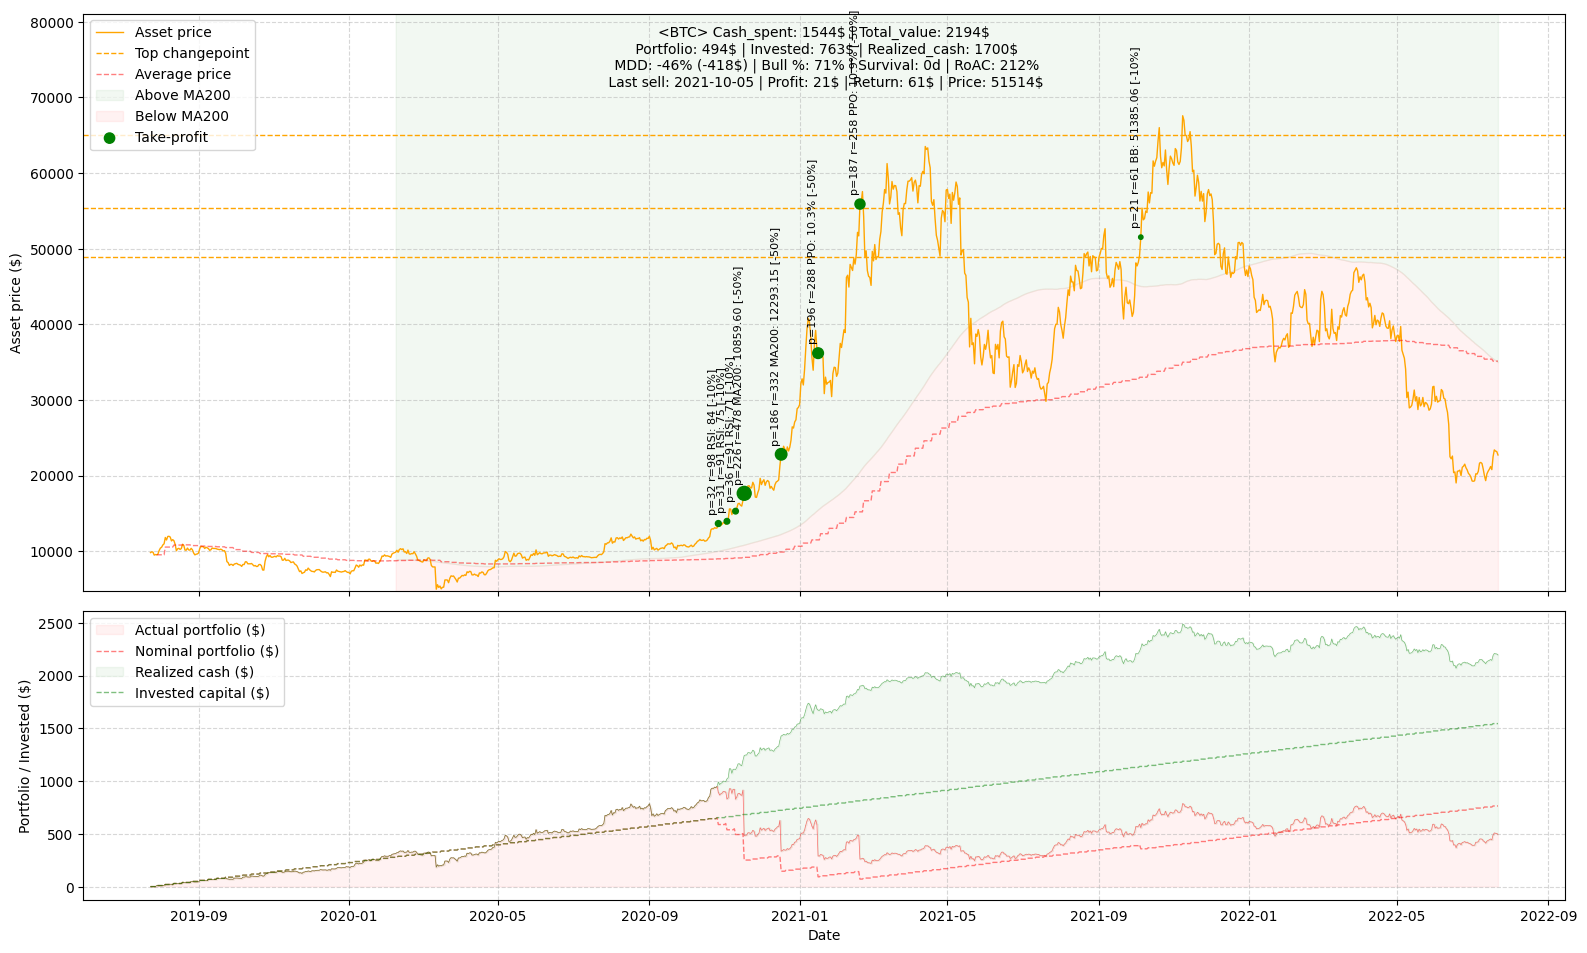

01:25:39 - cmdstanpy - INFO - Chain [1] start processing
01:25:39 - cmdstanpy - INFO - Chain [1] done processing


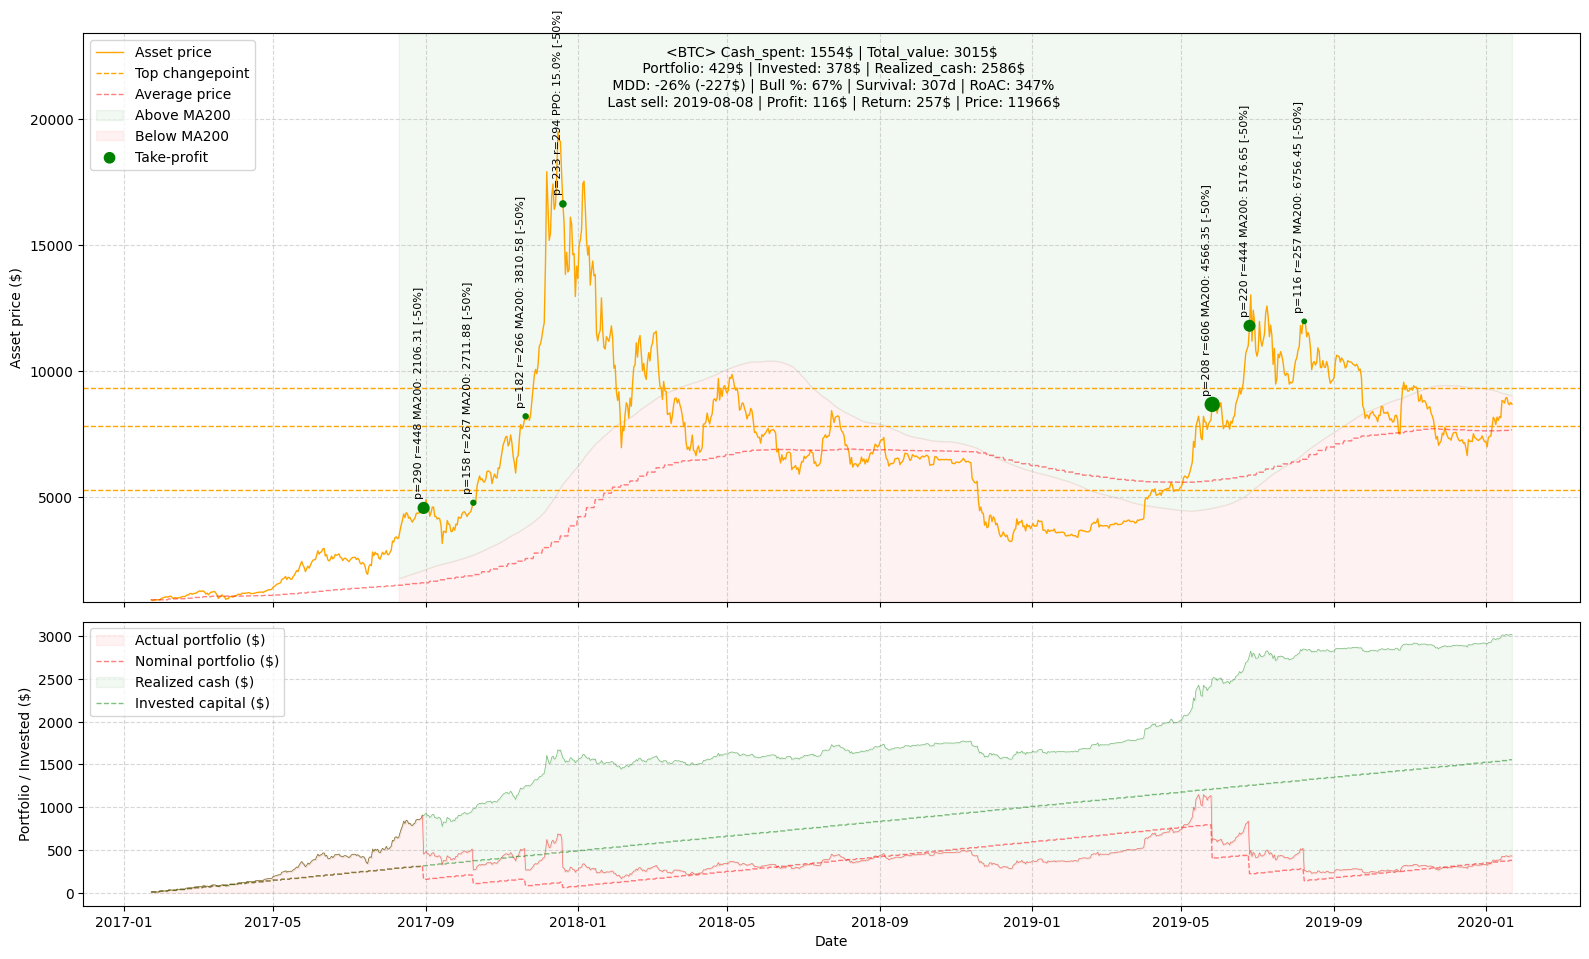

01:25:40 - cmdstanpy - INFO - Chain [1] start processing
01:25:40 - cmdstanpy - INFO - Chain [1] done processing


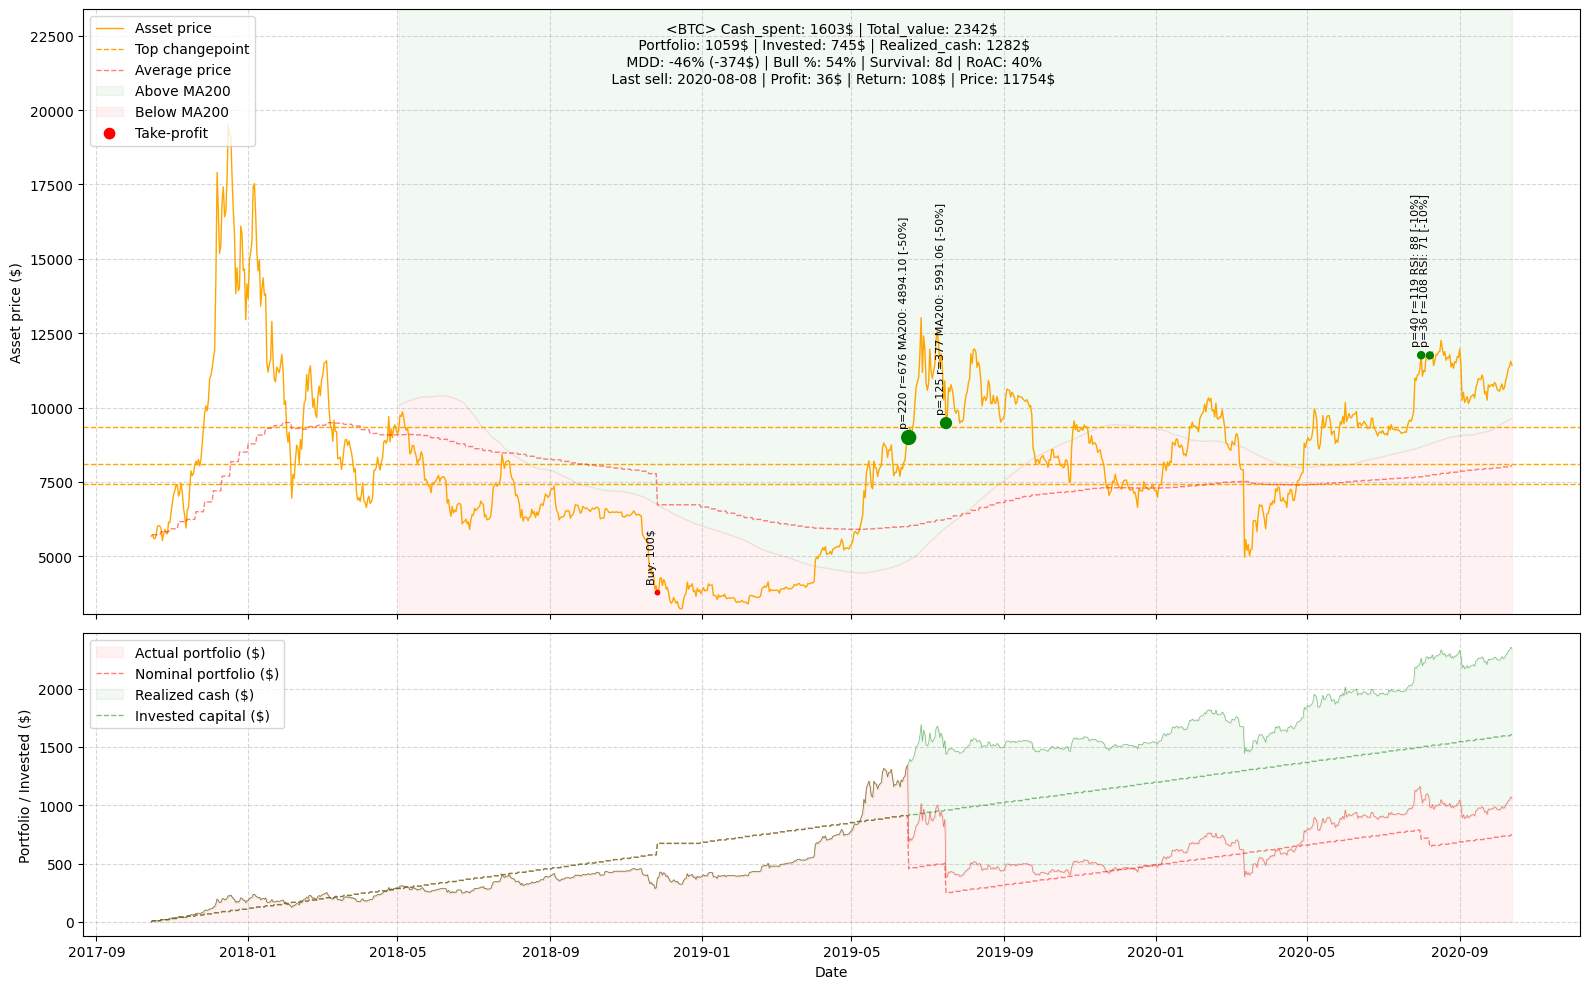

01:25:40 - cmdstanpy - INFO - Chain [1] start processing
01:25:40 - cmdstanpy - INFO - Chain [1] done processing


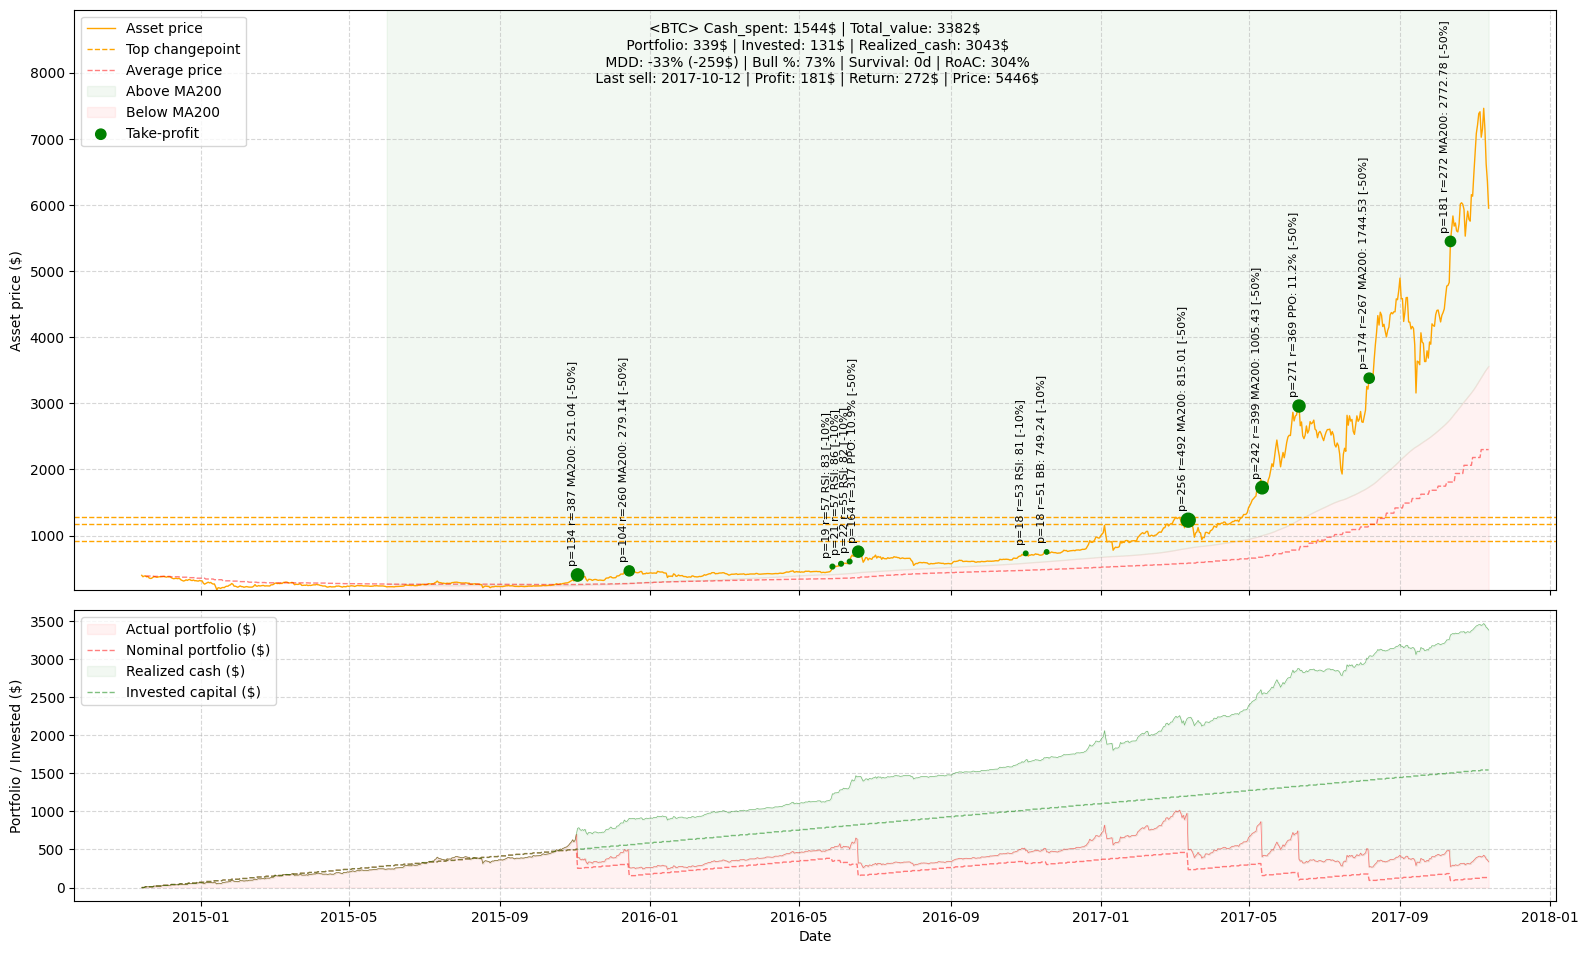

01:25:41 - cmdstanpy - INFO - Chain [1] start processing
01:25:41 - cmdstanpy - INFO - Chain [1] done processing


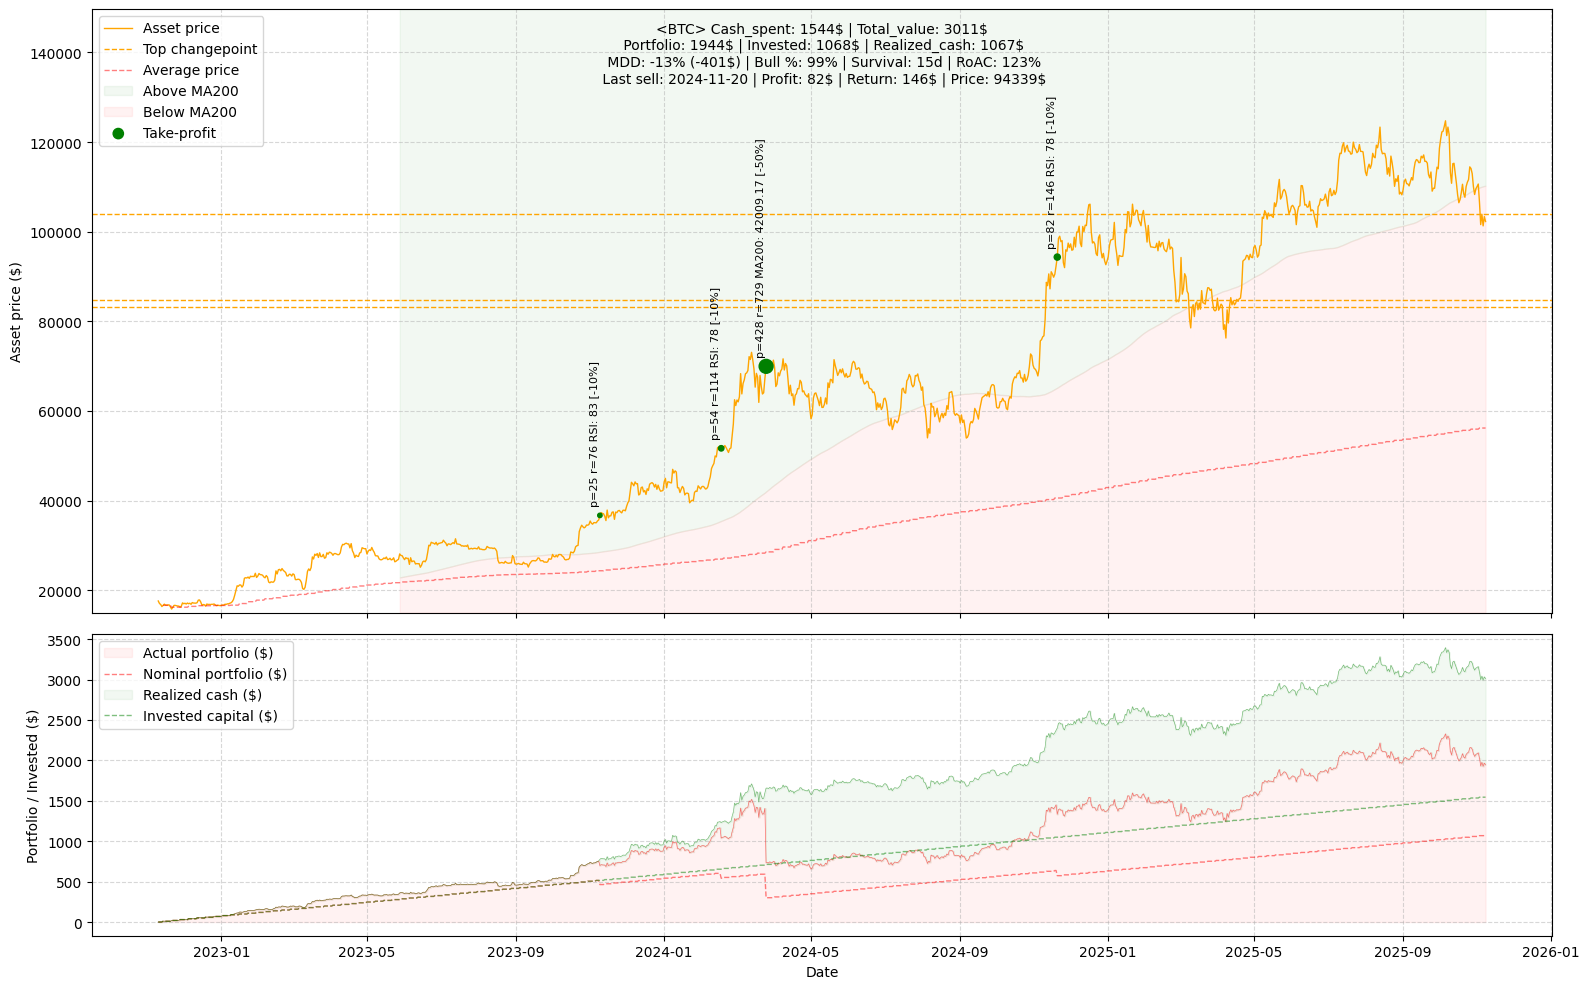

01:25:41 - cmdstanpy - INFO - Chain [1] start processing
01:25:42 - cmdstanpy - INFO - Chain [1] done processing


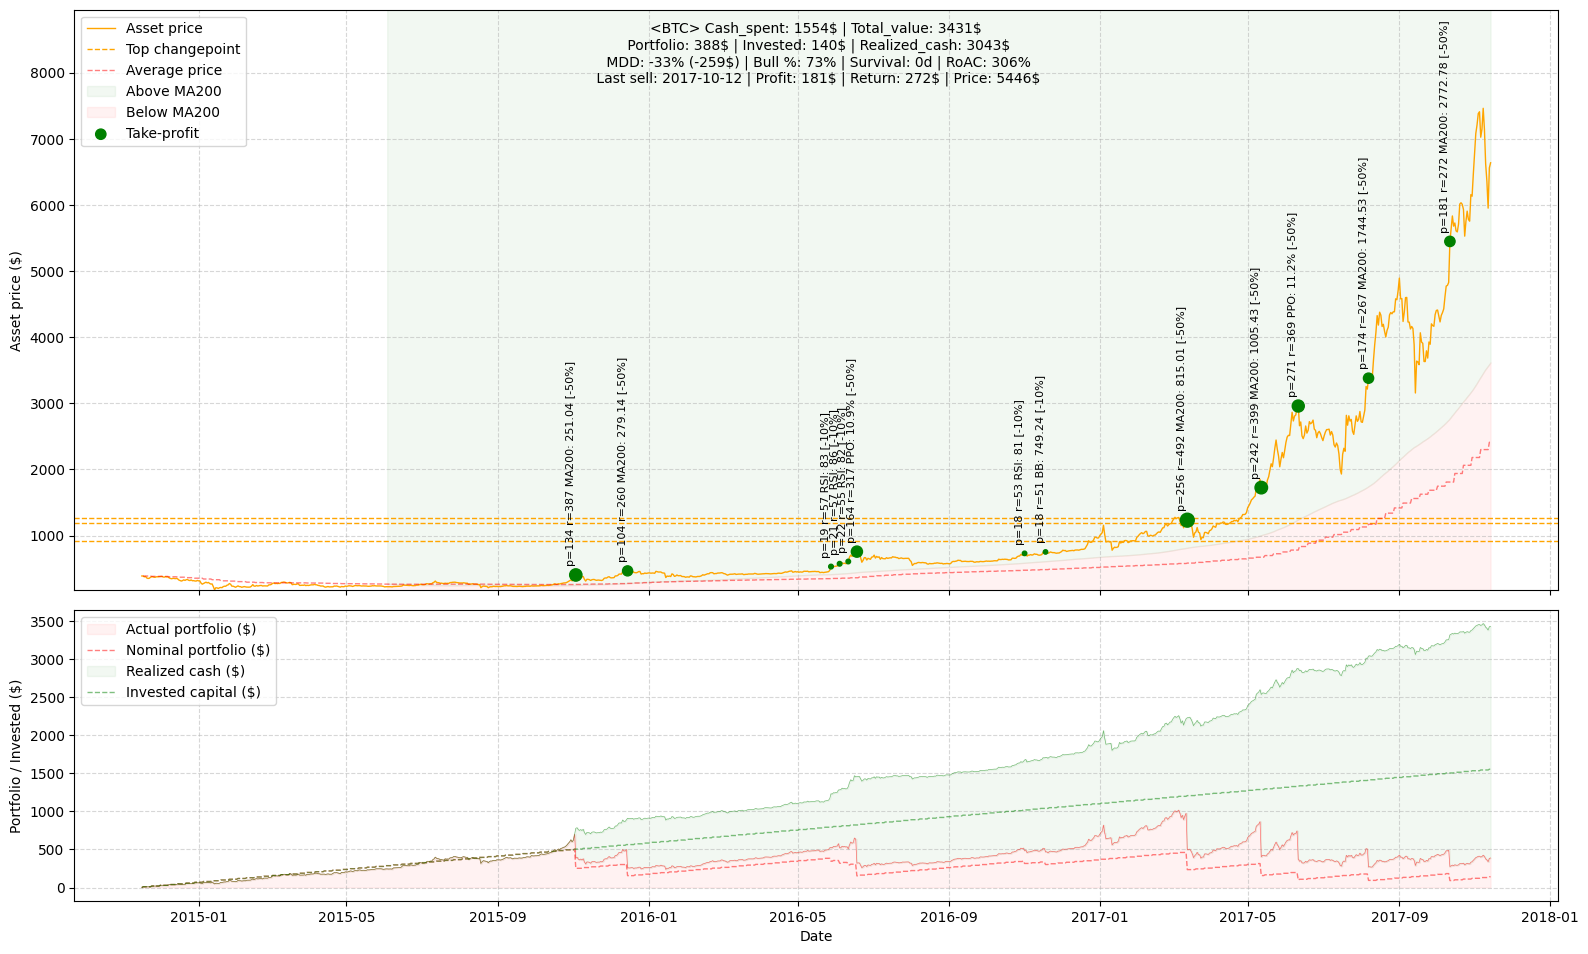

01:25:42 - cmdstanpy - INFO - Chain [1] start processing
01:25:42 - cmdstanpy - INFO - Chain [1] done processing


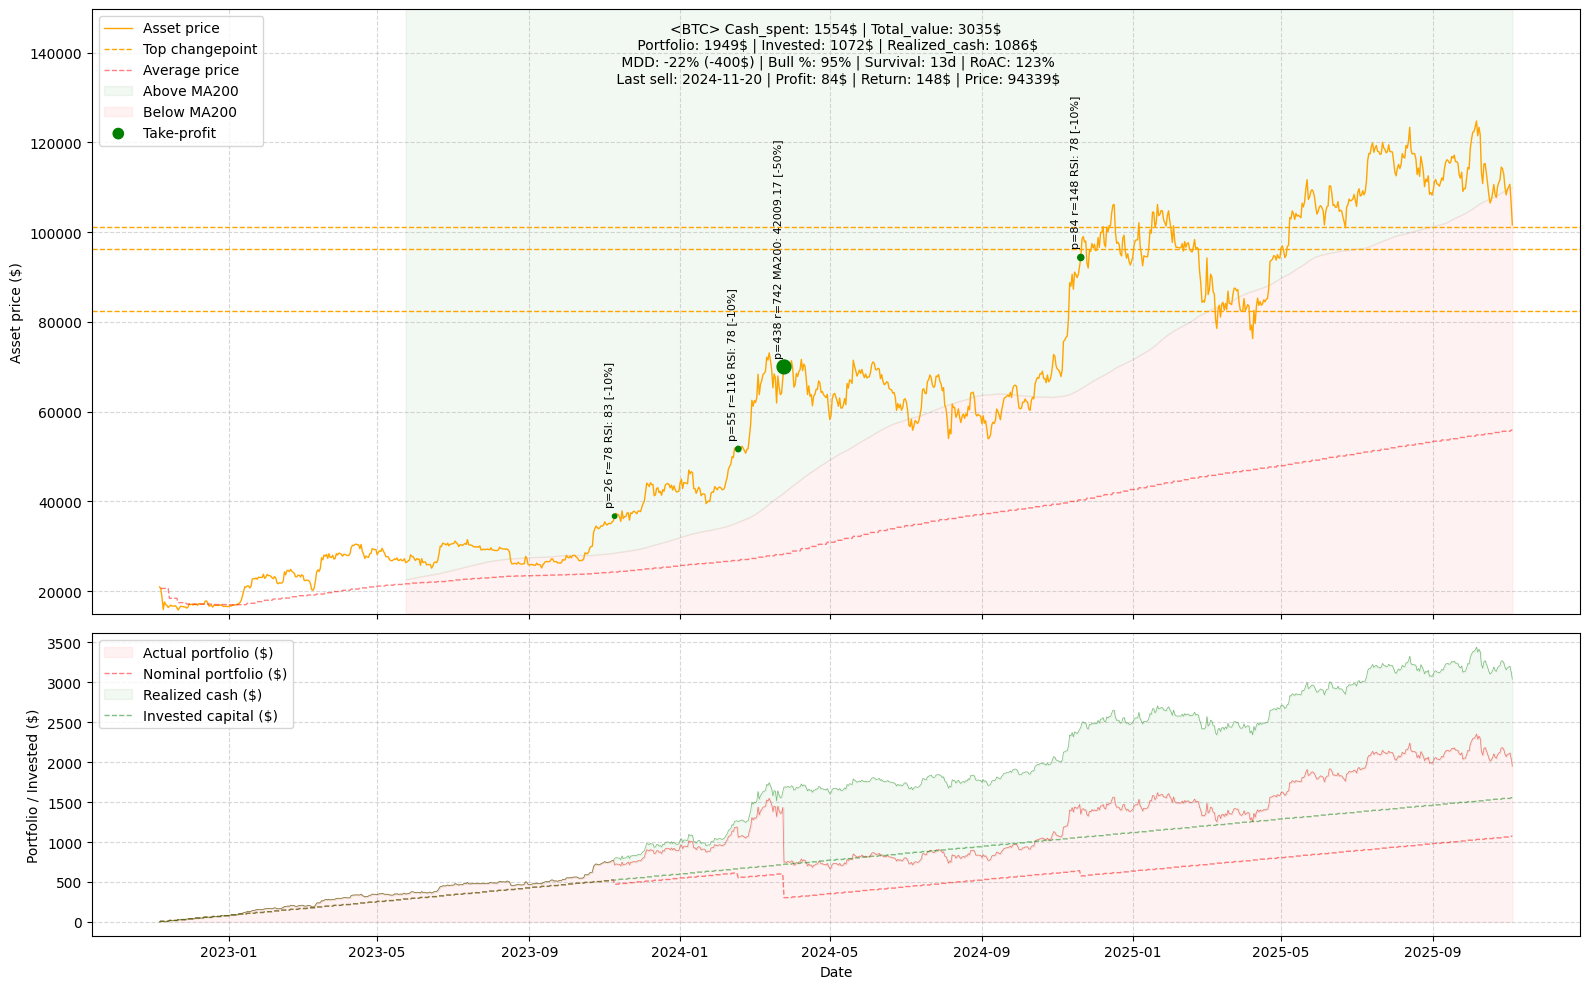

01:25:43 - cmdstanpy - INFO - Chain [1] start processing
01:25:43 - cmdstanpy - INFO - Chain [1] done processing


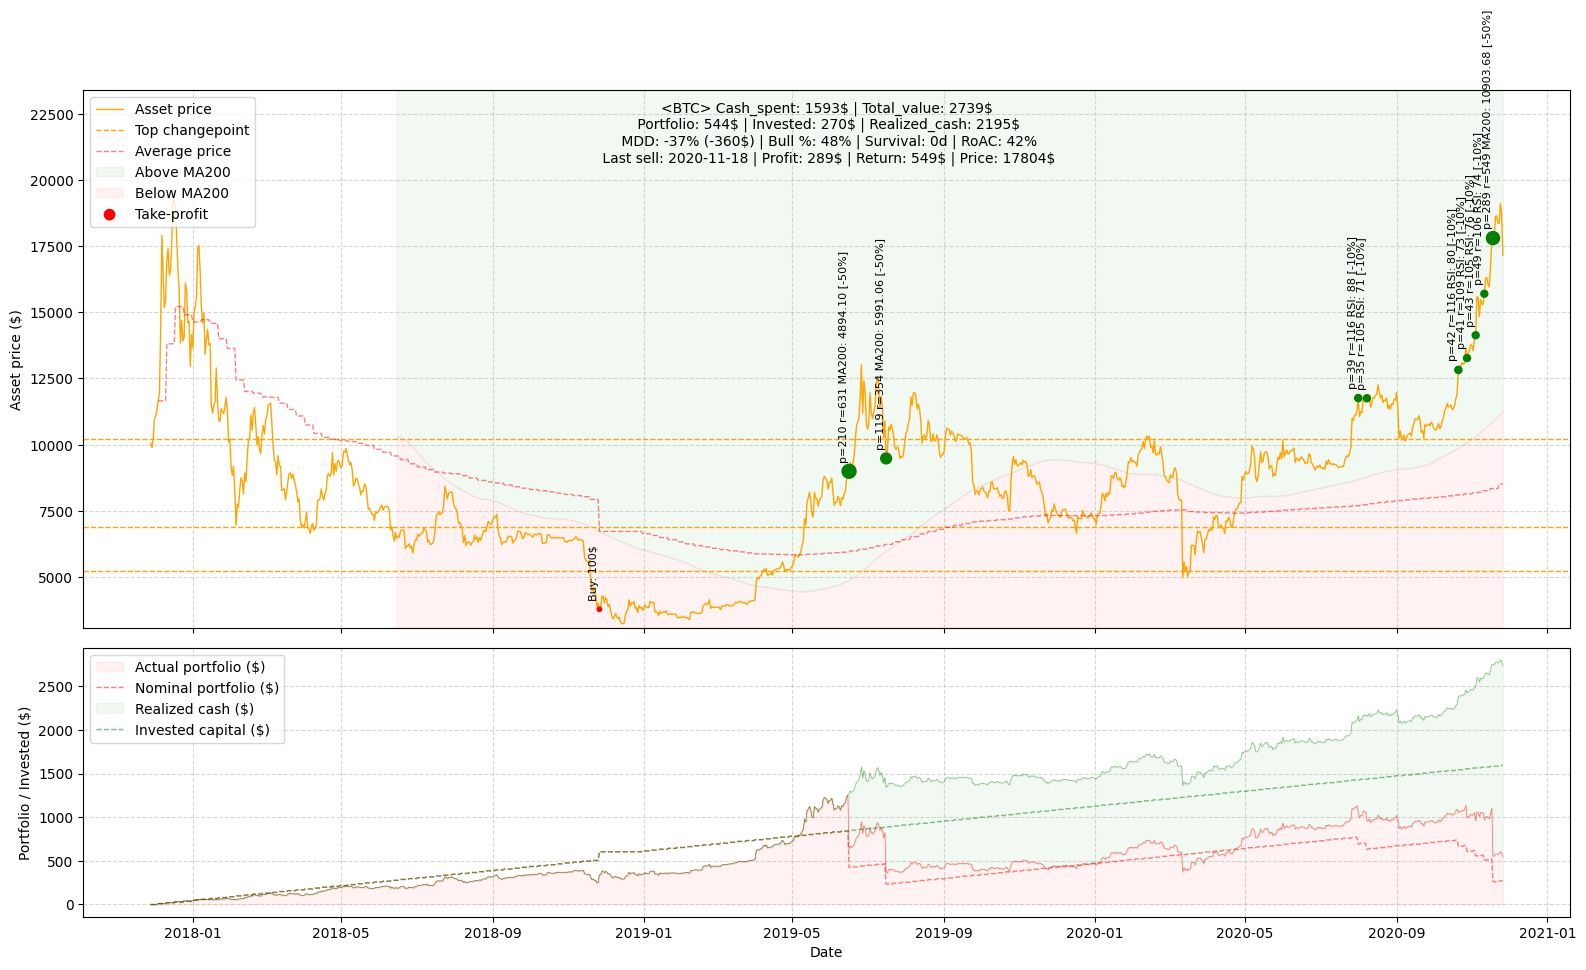

01:25:43 - cmdstanpy - INFO - Chain [1] start processing
01:25:43 - cmdstanpy - INFO - Chain [1] done processing


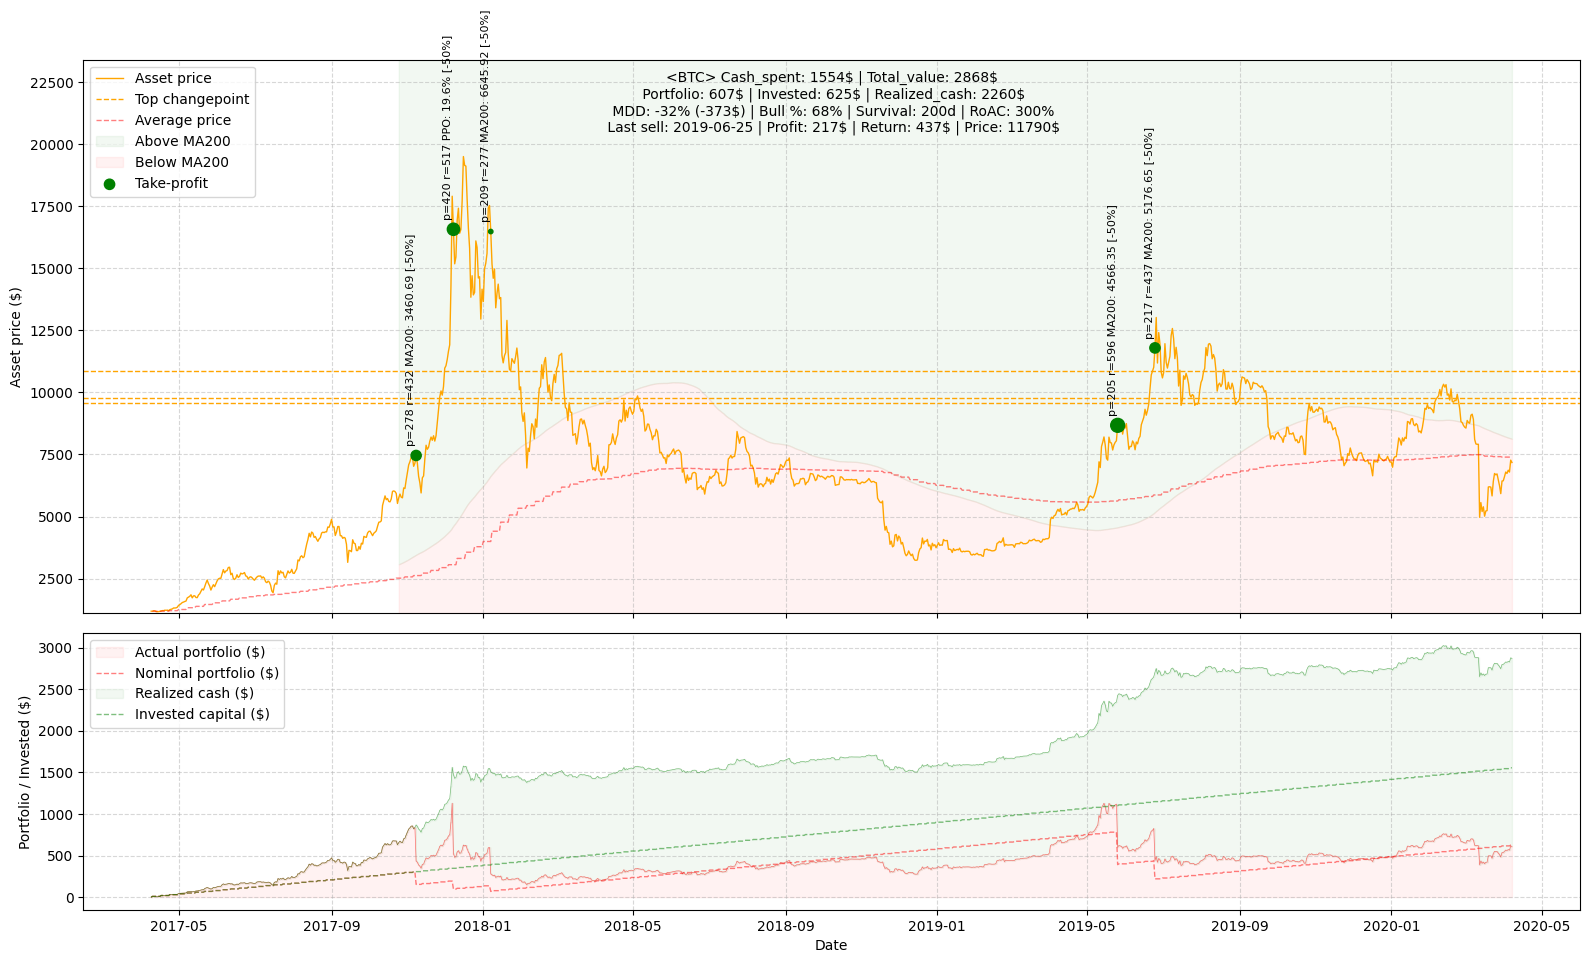

,Target,Cash_spent,Realized_cash,Portfolio,Invested,Total_value,Bull_history,Avg_price,Num_take_profits,MDD,MDD_usd,MA200_survival_days,RoAC,Period,Start,End
0,BTC,1554,3256,323,290,3579,94,6872.788380,14,-22,-276,0.000000,567,1,2015-06-07,2018-06-05
1,BTC,1544,1700,494,763,2194,71,35123.236118,8,-46,-418,0.000000,212,2,2019-07-24,2022-07-22
2,BTC,1554,2586,429,378,3015,67,7662.766464,7,-26,-227,307.000000,347,3,2017-01-23,2020-01-22
3,BTC,1603,1282,1059,745,2342,54,8036.009368,5,-46,-374,8.000000,40,4,2017-10-15,2020-10-13
4,BTC,1544,3043,339,131,3382,73,2299.332824,13,-33,-259,0.000000,304,5,2014-11-14,2017-11-12
5,BTC,1544,1067,1944,1068,3011,99,56188.508604,4,-13,-401,15.285714,123,6,2022-11-10,2025-11-08
6,BTC,1554,3043,388,140,3431,73,2409.249191,13,-33,-259,0.000000,306,7,2014-11-16,2017-11-14
7,BTC,1554,1086,1949,1072,3035,95,55863.725137,4,-22,-400,13.500000,123,8,2022-11-06,2025-11-04
8,BTC,1593,2195,544,270,2739,48,8512.509037,10,-37,-360,0.000000,42,9,2017-11-28,2020-11-26
9,BTC,1554,2260,607,625,2868,68,7392.539626,5,-32,-373,200.500000,300,10,2017-04-09,2020-04-07


In [8]:
all_metrics = []
last_result = None
last_metrics = None

for p in periods:
    period_prices = p["prices"]

    try:
        bt = BacktestDCA(
        target=target_asset,
        prices=period_prices,
        strategy=strategy
        )
        result, metrics = bt.run()
        ploter(metrics=metrics, history=result)
    except Exception as e:
        print(f"Error backtesting {target_asset} on period {p['period_id']}: {e}")
        continue

    metrics = metrics.copy()
    metrics["Period"] = p["period_id"]
    metrics["Start"] = p["start"]
    metrics["End"] = p["end"]
    all_metrics.append(metrics)

    last_result = result
    last_metrics = metrics

summary = pd.DataFrame(all_metrics)
summary

In [9]:
last_result

,Price,Portfolio_qty,Cost_basis,Cash_spent,Profit,Returns,Realized_cash,Trigger_msg,Portfolio,Average_price,Total_value
Date,,,,,,,,,,,
2017-04-09,1187.869995,0.000000,0.000000,0.0,0.0,0.0,0.000000,,0.000000,NaN,0.000000
2017-04-10,1187.130005,0.008339,9.900000,9.9,0.0,0.0,0.000000,,9.900000,1187.130005,9.900000
2017-04-11,1205.010010,0.008339,9.900000,9.9,0.0,0.0,0.000000,,10.049109,1187.130005,10.049109
2017-04-12,1200.369995,0.008339,9.900000,9.9,0.0,0.0,0.000000,,10.010414,1187.130005,10.010414
2017-04-13,1169.280029,0.008339,9.900000,9.9,0.0,0.0,0.000000,,9.751141,1187.130005,9.751141
...,...,...,...,...,...,...,...,...,...,...,...
2020-04-03,6733.387207,0.083300,615.965625,1544.4,0.0,0.0,2260.845479,,560.893587,7394.513251,2821.739065
2020-04-04,6867.527344,0.083300,615.965625,1544.4,0.0,0.0,2260.845479,,572.067509,7394.513251,2832.912987
2020-04-05,6791.129395,0.083300,615.965625,1544.4,0.0,0.0,2260.845479,,565.703532,7394.513251,2826.549010


In [10]:
last_metrics

{'Target': 'BTC',
 'Cash_spent': 1554,
 'Realized_cash': 2260,
 'Portfolio': 607,
 'Invested': 625,
 'Total_value': 2868,
 'Bull_history': 68,
 'Avg_price': np.float64(7392.5396258711935),
 'Num_take_profits': 5,
 'MDD': -32,
 'MDD_usd': -373,
 'MA200_survival_days': 200.49999999999997,
 'RoAC': 300,
 'Period': 10,
 'Start': Timestamp('2017-04-09 00:00:00'),
 'End': Timestamp('2020-04-07 00:00:00')}